<a href="https://colab.research.google.com/github/bavucadoz/244107020162_ML_2026/blob/main/Minggu14/P01_Week14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Praktikum 1**
*Pada praktikum ini kita akan membuat model klasifikasi CNN sederhana pada kasus citra kucing dan anjing, dengan dataset data citra anjing dan kucing yang telah dibagi menjadi data training dan data testing.*


---



## **Langkah 1 - Import Library**

In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).




---


## **Langkah 2 - Pra Pengolahan Data**

**Langkah 2.1 - Pra Pengolahan Data Training**

In [4]:
train_datagen = ImageDataGenerator(rescale = 1./255,
                                   shear_range = 0.2,
                                   zoom_range = 0.2,
                                   horizontal_flip = True)
training_set = train_datagen.flow_from_directory('/content/drive/MyDrive/dataset/training_set',
                                                 target_size = (64, 64),
                                                 batch_size = 32,
                                                 class_mode = 'binary')

Found 8001 images belonging to 2 classes.


**Langkah 2.2 - Pra Pengolahan Data Testing**

In [5]:
test_datagen = ImageDataGenerator(rescale = 1./255)
test_set = test_datagen.flow_from_directory('/content/drive/MyDrive/dataset/test_set',
                                            target_size = (64, 64),
                                            batch_size = 32,
                                            class_mode = 'binary')

Found 2000 images belonging to 2 classes.




---


## **Langkah 3 - Pembuatan Model CNN**

**Langkah 3.1  - Inisiasi Model CNN**

In [6]:
cnn = tf.keras.models.Sequential()

**Langkah 3.2  - Pembuatan Layer Konvolusi 1**

In [7]:
cnn.add(tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu', input_shape=[64, 64, 3]))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


**Langkah 3.3  - Pembuatan Layer Pooling 1**

In [8]:
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

**Langkah 3.4  - Pembuatan Layer Konvolusi 2 dan Pooling 2**

In [9]:
cnn.add(tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

**Langkah 3.5  - Flattening**

In [10]:
cnn.add(tf.keras.layers.Flatten())

**Langkah 3.6  - Fully Connected Layer 1 (Input)**

In [11]:
cnn.add(tf.keras.layers.Dense(units=128, activation='relu'))

**Langkah 3.7  - Fully Connected Layer 2 (Output)**

In [12]:
cnn.add(tf.keras.layers.Dense(units=1, activation='sigmoid'))

**Langkah 3.8  - Compile Model CNN**

In [13]:
cnn.compile(optimizer = 'adam', loss = 'binary_crossentropy', metrics = ['accuracy'])



---


## **Langkah 4 - Fit CNN**

In [14]:
cnn.fit(x = training_set, validation_data = test_set, epochs = 25)

Epoch 1/25
251/251 ━━━━━━━━━━━━━━━━━━━━ 306s 1s/step - accuracy: 0.5744 - loss: 0.6771 - val_accuracy: 0.6120 - val_loss: 0.6539
Epoch 2/25
251/251 ━━━━━━━━━━━━━━━━━━━━ 86s 343ms/step - accuracy: 0.6503 - loss: 0.6335 - val_accuracy: 0.6590 - val_loss: 0.6200
Epoch 3/25
251/251 ━━━━━━━━━━━━━━━━━━━━ 83s 332ms/step - accuracy: 0.6937 - loss: 0.5878 - val_accuracy: 0.7280 - val_loss: 0.5725
Epoch 4/25
251/251 ━━━━━━━━━━━━━━━━━━━━ 86s 342ms/step - accuracy: 0.7204 - loss: 0.5512 - val_accuracy: 0.7320 - val_loss: 0.5483
Epoch 5/25
251/251 ━━━━━━━━━━━━━━━━━━━━ 87s 347ms/step - accuracy: 0.7292 - loss: 0.5369 - val_accuracy: 0.7400 - val_loss: 0.5275
Epoch 6/25
251/251 ━━━━━━━━━━━━━━━━━━━━ 85s 339ms/step - accuracy: 0.7535 - loss: 0.5063 - val_accuracy: 0.7345 - val_loss: 0.5412
Epoch 7/25
251/251 ━━━━━━━━━━━━━━━━━━━━ 83s 330ms/step - accuracy: 0.7637 - loss: 0.4844 - val_accuracy: 0.7725 - val_loss: 0.4865
Epoch 8/25
251/251 ━━━━━━━━━━━━━━━━━━━━ 84s 336ms/step - accuracy: 0.7789 - loss: 0.4



---


## **Langkah 5 - Prediksi dengan 1 Citra**

In [15]:
import numpy as np
from keras.preprocessing import image
test_image = image.load_img('/content/drive/MyDrive/dataset/single_prediction/cat_or_dog_1.jpg', target_size = (64, 64))
test_image = image.img_to_array(test_image)
test_image = np.expand_dims(test_image, axis = 0)
result = cnn.predict(test_image)
training_set.class_indices
if result[0][0] == 1:
  prediction = 'dog'
else:
  prediction = 'cat'

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step


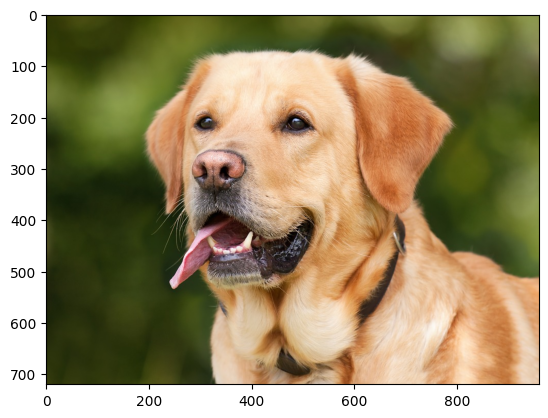

In [20]:
import matplotlib.pyplot as plt
from keras.preprocessing import image

img_path = '/content/drive/MyDrive/dataset/single_prediction/cat_or_dog_1.jpg'
plt.imshow(image.load_img(img_path))

In [16]:
print("Hasil Prediksi:", prediction)

Hasil Prediksi: dog
